In [1]:
import numpy as np
import torch
import random
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
import torch.optim as optim

from load_data import load_data
from train import train_model, test_model_simple, train_hebbian_unsupervised, train_oja_unsupervised, train_3factor_oja, train_oja_unsupervised_adler, train_oja_switch
from utils import orient_weights, find_tuning, plot_weights, find_bias_simple, test_learning_rule, compute_cp, compute_noise_corr, compute_readout_weights, compute_d_prime, compute_dprime_cp_correlation


In [11]:
seed = 100
n_neurons = 1000
batchsize = 50
n_epochs = 10
optimize = "Adam"
crit = "BCE"

gain_to_add = 0.0
p = 0.99
p_over = 0.8

noise_common = 2.0
noise_group = 2.0
noise_independent = 5.0

phase = "1"
centering = False
clip_fr = True

In [12]:
torch.manual_seed(seed)
random.seed(seed)
np.random.seed(seed)

device = 'cpu'

if p_over == 0.5:
    phase = '2'
    

In [13]:
train_dataloader, test_dataloader, X_train, y_train, X_test, y_test, tuning_groups = load_data(n_neurons = n_neurons, p_over = p_over, phase=phase, gain_to_add = gain_to_add, noise_or=noise_group, noise_ur = noise_group, noise_bg = noise_common, noise_independent = noise_independent, centering = centering, clip_fr = clip_fr, seed=seed)


In [14]:
neurons_tuned_stim0, neurons_tuned_stim1, neurons_untuned = find_tuning(torch.tensor(X_train).squeeze(), torch.tensor(y_train), min_abs_dprime=0.2, seed=seed); tunings = [neurons_tuned_stim0, neurons_tuned_stim1, neurons_untuned]
neurons_ordered = neurons_tuned_stim1 + neurons_tuned_stim0


In [15]:
X_test_ = X_test[:, neurons_ordered]
X_train_ = X_train[:, neurons_ordered]

Cov = (X_test_ - X_test_.mean(0)).T.dot(X_test_ - X_test_.mean(0))
evals, evecs = np.linalg.eigh(Cov)
pc1 = evecs[:, -1]

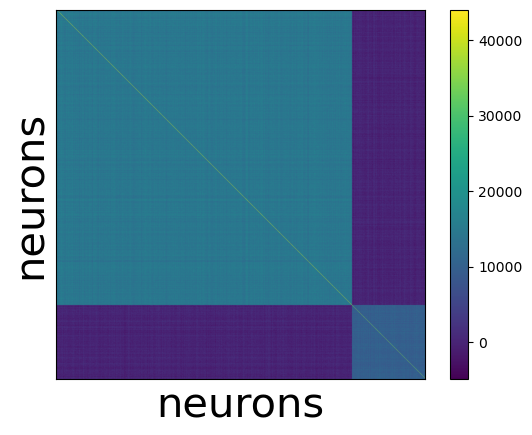

In [16]:
plt.imshow(Cov)
plt.colorbar()

plt.xticks([])
plt.yticks([])
plt.xlabel("neurons", fontsize=30)
plt.ylabel("neurons", fontsize=30)
plt.savefig("saved_figs/covariance_phase" + phase + ".pdf")


In [17]:
mean_stim1_pop1 = X_train[:500, neurons_tuned_stim1].mean()
mean_stim1_pop2 = X_train[:500, neurons_tuned_stim0].mean()

mean_stim2_pop1 = X_train[500:, neurons_tuned_stim1].mean()
mean_stim2_pop2 = X_train[500:, neurons_tuned_stim0].mean()


(31.226875002262847, 31.226875002262847, 25.94891712200939, 25.94891712200939)

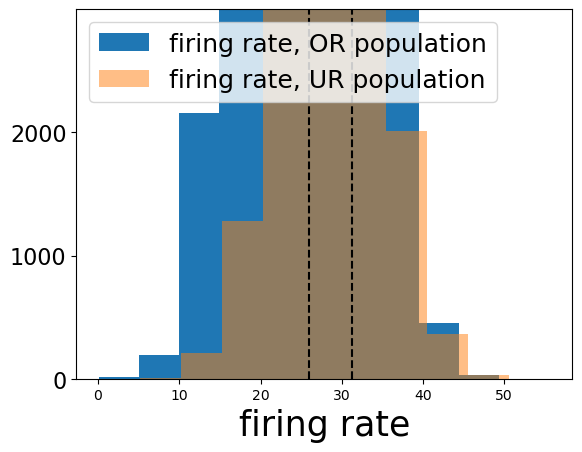

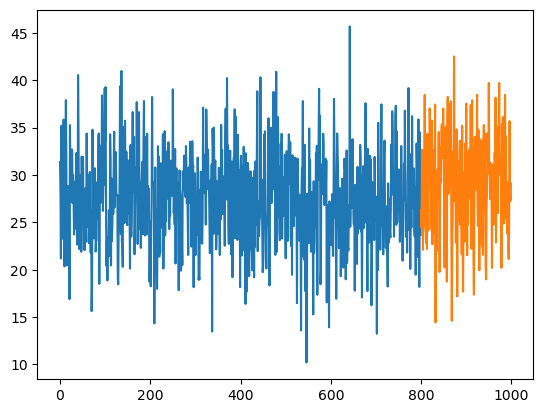

In [18]:
plt.figure()
plt.hist(X_train[550:650, neurons_tuned_stim1].flatten(), label="firing rate, OR population")
plt.hist(X_train[550:650, neurons_tuned_stim0].flatten(), alpha=0.5, label="firing rate, UR population")
plt.axvline(mean_stim1_pop1, color='k', linestyle='--')
plt.axvline(mean_stim1_pop2, color='k', linestyle='--')

plt.ylim([0, 3000])
#plt.ylim([24,36])
plt.yticks(np.arange(0, 3000, 1000), fontsize=16)
plt.xlabel("firing rate", fontsize=25)
plt.legend(fontsize=18, loc='upper left')
plt.savefig("saved_figs/firing_rateHist_phase" + phase + "_stim1.pdf",  bbox_inches="tight", pad_inches=0.02)

plt.figure()
#plt.plot(X_train[0, :len(neurons_tuned_stim1)].flatten(), label="firing rate, OR population")
#plt.plot(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim1)+len(neurons_tuned_stim0)), X_train[0, len(neurons_tuned_stim1):].flatten(), label="firing rate, OR population")

plt.plot(X_train[900, neurons_tuned_stim1].flatten(), label="firing rate, OR population")
plt.plot(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim1)+len(neurons_tuned_stim0)), X_train[900, neurons_tuned_stim0].flatten(), label="firing rate, OR population")

X_train[:500, neurons_tuned_stim1].mean(), X_train[:500, neurons_tuned_stim1].mean(), X_train[500:, neurons_tuned_stim1].mean(), X_train[500:, neurons_tuned_stim1].mean()




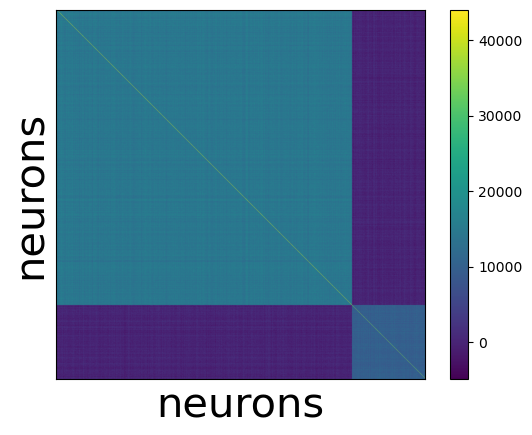

In [19]:
plt.imshow(Cov)
plt.colorbar()

plt.xticks([])
plt.yticks([])
plt.xlabel("neurons", fontsize=30)
plt.ylabel("neurons", fontsize=30)
plt.savefig("saved_figs/covariance_phase" + phase + ".pdf")


In [ ]:
separator = "_"
experiment = separator.join(["Oja", "phase" + phase])
switch = True

parameter_list = {}
if phase == "2" or "3":
    parameter_list["criterion"] = crit; parameter_list["p_over"] = p_over; parameter_list["W_init"] = "no_initW" #"initW1"
    parameter_list["noise_gp_co_ind"] = [noise_group, noise_common, noise_independent]; parameter_list["seed"] = seed; parameter_list["phase"] = phase; parameter_list["centering"] = "_centering" if centering else "_no_centering"

if "Hebbian" in experiment:
    w, b, eta, acc_arr = train_hebbian_unsupervised(X_train, y_train, phase=phase, parameter_list = parameter_list)
elif "Oja" in experiment and switch == False:
    w, b, eta, acc_arr = train_oja_unsupervised(X_train, y_train, phase=phase, parameter_list = parameter_list)
elif "3factor" in experiment:
    w, b, eta, acc_arr, err_arr = train_3factor_oja(X_train, y_train, phase=phase, parameter_list = parameter_list)


if "Oja" in experiment and switch:   
    for phase in ["1", "2", "3"]:
        if phase == "2":
            print("phase", phase)
            _, _, X_train_phase2, y_train_phase2, X_test, y_test, tuning_groups = load_data(n_neurons = n_neurons, p_over = 0.5, phase=phase, gain_to_add = gain_to_add, noise_or=noise_group, noise_ur = noise_group, noise_bg = noise_common, noise_independent = noise_independent, centering = False, seed=seed)
            neurons_tuned_stim0_phase2, neurons_tuned_stim1_phase2, neurons_untuned_phase2 = find_tuning(torch.tensor(X_train_phase2).squeeze(), torch.tensor(y_train_phase2), min_abs_dprime=0.2, seed=seed); tunings = [neurons_tuned_stim0, neurons_tuned_stim1, neurons_untuned]
            neurons_ordered_phase2 = neurons_tuned_stim1_phase2 + neurons_tuned_stim0_phase2

            X_train_phase2 = torch.tensor(X_train_phase2).float(); y_train_phase2 = torch.tensor(y_train_phase2)
            w, b, eta, acc_arr, gain_arr = train_oja_unsupervised_adler(X_train_phase2, y_train_phase2, student_w_init = weight_phase1, phase=phase, b_init=b)
            weight_phase2 = w.squeeze()
        elif phase == "3":
            print("phase", phase)
            w, b, eta, acc_arr, gain_arr = train_oja_unsupervised_adler(X_train, y_train, student_w_init = weight_phase2, phase=phase, b_init = b)
            weight_phase3 = w.squeeze()
        elif phase == "1":
            print("phase", phase)
            X_train = torch.tensor(X_train).float(); y_train = torch.tensor(y_train)
            w, b, eta, acc_arr, gain_arr = train_oja_unsupervised_adler(X_train, y_train, phase=phase)
            weight_phase1 = w.squeeze()

In [ ]:
eta

In [ ]:
w = w.squeeze()
plt.bar(np.arange(len(neurons_tuned_stim1)), w[neurons_tuned_stim1].flatten())
plt.bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), w[neurons_tuned_stim0].flatten())



In [ ]:
plt.bar(np.arange(len(neurons_tuned_stim1)), pc1[:len(neurons_tuned_stim1)].flatten())
plt.bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), pc1[len(neurons_tuned_stim1):].flatten())


In [ ]:
fig, axs = plt.subplots(1,3)

axs[0].bar(np.arange(len(neurons_tuned_stim1)), weight_phase1[neurons_tuned_stim1].flatten())
axs[0].bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), weight_phase1[neurons_tuned_stim0].flatten())

axs[1].bar(np.arange(len(neurons_tuned_stim1_phase2)), weight_phase2[neurons_tuned_stim1_phase2].flatten())
axs[1].bar(np.arange(len(neurons_tuned_stim1_phase2), len(neurons_tuned_stim0_phase2)+len(neurons_tuned_stim1_phase2)), weight_phase2[neurons_tuned_stim0_phase2].flatten())

axs[2].bar(np.arange(len(neurons_tuned_stim1)), weight_phase3[neurons_tuned_stim1].flatten())
axs[2].bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), weight_phase3[neurons_tuned_stim0].flatten())


In [ ]:
sol = torch.tensor(X_train_phase2).float() @ weight_phase2.float()
((sol[y_train_phase2==1]<0).sum() + (sol[y_train_phase2==0]>0).sum())/len(y_train_phase2)

In [ ]:
weight_phase2.max(), weight_phase2.min()

In [20]:
separator = "_"
experiment = separator.join(["Oja", "phase" + phase])
switch = True

if "Oja" in experiment and switch:   
    for phase in ["1", "2", "3"]:
        if phase == "2":
            print("phase", phase)
            _, _, X_train_phase2, y_train_phase2, X_test, y_test, tuning_groups = load_data(n_neurons = n_neurons, p_over = 0.5, phase=phase, gain_to_add = gain_to_add, noise_or=noise_group, noise_ur = noise_group, noise_bg = noise_common, noise_independent = noise_independent, centering = False, clip_fr = clip_fr, seed=seed)
            neurons_tuned_stim0_phase2, neurons_tuned_stim1_phase2, neurons_untuned_phase2 = find_tuning(torch.tensor(X_train_phase2).squeeze(), torch.tensor(y_train_phase2), min_abs_dprime=0.2, seed=seed); tunings = [neurons_tuned_stim0, neurons_tuned_stim1, neurons_untuned]
            neurons_ordered_phase2 = neurons_tuned_stim1_phase2 + neurons_tuned_stim0_phase2

            X_train_phase2 = torch.tensor(X_train_phase2).float(); y_train_phase2 = torch.tensor(y_train_phase2)
            w1, b1, w2, b2, eta, acc_arr_p2, gate_arr_p2, err_arr_p2, state_p2 = train_oja_switch(X_train_phase2, y_train_phase2, student_w_init = weight_phase1)
            weight_phase2 = w1.squeeze() if gate_arr_p2[-1]<0.1 else w2.squeeze()
        elif phase == "3":
            print("phase", phase)
            w1, b1, w2, b2, eta, acc_arr_p3, gate_arr_p3, err_arr_p3, state_p3 = train_oja_switch(X_train, y_train, student_w_init = weight_phase2)
            weight_phase3 = w1.squeeze() if gate_arr_p3[-1]<0.1 else w2.squeeze()
        elif phase == "1":
            print("phase", phase)
            X_train = torch.tensor(X_train).float(); y_train = torch.tensor(y_train)
            w1, b1, w2, b2, eta, acc_arr_p1, gate_arr_p1, err_arr_p1, state_p1 = train_oja_switch(X_train, y_train)
            weight_phase1 = w1.squeeze() if gate_arr_p1[-1]<0.1 else w2.squeeze()

phase 1
take weights from here...: None
i=  100  acc=0.75  e1=0.221  e2=0.375  u1=0.514  u2=0.000  g=0.000
i=  200  acc=0.78  e1=0.185  e2=0.424  u1=0.525  u2=0.000  g=0.000
i=  300  acc=0.68  e1=0.217  e2=0.380  u1=0.479  u2=0.000  g=0.000
i=  400  acc=0.71  e1=0.346  e2=0.331  u1=0.310  u2=0.000  g=0.000
i=  500  acc=0.73  e1=0.211  e2=0.197  u1=0.535  u2=0.000  g=0.000
i=  600  acc=0.69  e1=0.343  e2=0.337  u1=0.314  u2=0.000  g=0.000
i=  700  acc=0.76  e1=0.198  e2=0.140  u1=0.499  u2=0.000  g=0.000
i=  800  acc=0.67  e1=0.293  e2=0.273  u1=0.495  u2=0.003  g=0.007
i=  900  acc=0.68  e1=0.262  e2=0.160  u1=0.422  u2=0.001  g=0.001
i=  100  acc=0.76  e1=0.220  e2=0.172  u1=0.527  u2=0.000  g=0.000
i=  200  acc=0.78  e1=0.185  e2=0.170  u1=0.525  u2=0.000  g=0.000
i=  300  acc=0.68  e1=0.217  e2=0.098  u1=0.476  u2=0.001  g=0.003
i=  400  acc=0.71  e1=0.346  e2=0.102  u1=0.310  u2=0.004  g=0.013
i=  500  acc=0.74  e1=0.211  e2=0.183  u1=0.494  u2=0.014  g=0.027
i=  600  acc=0.69  e1=

<BarContainer object of 200 artists>

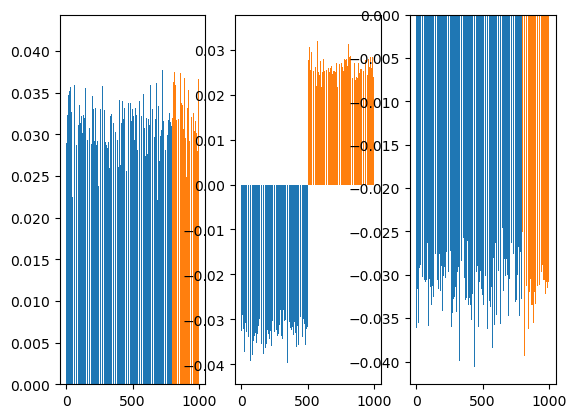

In [21]:
fig, axs = plt.subplots(1,3)

axs[0].bar(np.arange(len(neurons_tuned_stim1)), weight_phase1[neurons_tuned_stim1].flatten())
axs[0].bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), weight_phase1[neurons_tuned_stim0].flatten())

axs[1].bar(np.arange(len(neurons_tuned_stim1_phase2)), weight_phase2[neurons_tuned_stim1_phase2].flatten())
axs[1].bar(np.arange(len(neurons_tuned_stim1_phase2), len(neurons_tuned_stim0_phase2)+len(neurons_tuned_stim1_phase2)), weight_phase2[neurons_tuned_stim0_phase2].flatten())

axs[2].bar(np.arange(len(neurons_tuned_stim1)), weight_phase3[neurons_tuned_stim1].flatten())
axs[2].bar(np.arange(len(neurons_tuned_stim1), len(neurons_tuned_stim0)+len(neurons_tuned_stim1)), weight_phase3[neurons_tuned_stim0].flatten())


In [ ]:
gate_arr

In [ ]:
state_p1

In [ ]:
state_p2

In [ ]:
state_p3